# 01 · Ingest, clean and aggregate

**Goal:** turn 24 fortnightly TfL journey extracts (Jun 2025 to May 2026) into a clean journey table, load it into SQLite, and use SQL to build a complete station-hour demand table for the 40 busiest start stations.

Raw files are downloaded by `python src/download.py all` (≈1.5 GB of journeys, plus BikePoint, Open-Meteo and gov.uk bank holidays).

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from plotting import set_style, save, SERIES, INK, INK_2, NEUTRAL, BLUE_RAMP
set_style()
import cleaning, db
from config import JOURNEY_FILES, RAW, START_DATE, END_DATE, MIN_DURATION_S, MAX_DURATION_S

## 1. Check the schema before cleaning

TfL has changed the extract format several times. The 2015-2022 files used `Rental Id, Duration, StartStation Id, Start Date (dd/mm/yyyy)`; the current files use `Number, Start station number, Start date (yyyy-mm-dd), Total duration (ms)` and add `Bike model` (classic vs e-bike). Extracts also moved from **weekly to fortnightly** in 2022. `cleaning.COLUMN_MAP` maps both onto one standard schema, so older years can be added without code changes.

In [2]:
for f in (JOURNEY_FILES[0], JOURNEY_FILES[-1]):
    print(f, '->', list(pd.read_csv(RAW / 'journeys' / f, nrows=0).columns))
pd.read_csv(RAW / 'journeys' / JOURNEY_FILES[-1], nrows=3)

421JourneyDataExtract01Jun2025-15Jun2025.csv -> ['Number', 'Start date', 'Start station number', 'Start station', 'End date', 'End station number', 'End station', 'Bike number', 'Bike model', 'Total duration', 'Total duration (ms)']
444JourneyDataExtract17May2026-31May2026.csv -> ['Number', 'Start date', 'Start station number', 'Start station', 'End date', 'End station number', 'End station', 'Bike number', 'Bike model', 'Total duration', 'Total duration (ms)']


,Number,Start date,Start station number,Start station,End date,End station number,End station,Bike number,Bike model,Total duration,Total duration (ms)
0,158448278,2026-05-31 23:59,300227,"Timber Lodge, Queen Elizabeth Olympic Park",2026-06-01 02:17,300227,"Timber Lodge, Queen Elizabeth Olympic Park",50897,CLASSIC,2h 18m 16s,8296951
1,158448279,2026-05-31 23:59,200156,"Pott Street, Bethnal Green",2026-06-01 00:02,200083,"Pritchard's Road, Bethnal Green",90876,CLASSIC,3m 28s,208181
2,158448280,2026-05-31 23:59,200230,"Maplin Street, Mile End",2026-06-01 00:05,200013,"Aston Street, Stepney",55014,CLASSIC,5m 59s,359423


## 2. Combine and clean

Rules (thresholds live in `src/config.py`):

| Rule | Why |
|---|---|
| Drop duplicate rental ids | fortnightly extracts can overlap at the boundaries |
| Drop rows missing a timestamp, station or duration | unusable |
| Duration < 1 minute | false starts, immediate re-docks |
| Duration > 3 hours | lost, stolen or mis-docked bikes, not real demand |
| Same-dock round trip < 2 minutes | rider swapping a faulty bike |
| Remap retired station codes | see section 3 |

In [3]:
clean, stations, audit, raw = cleaning.run(start=pd.Timestamp(START_DATE),
                                           end=pd.Timestamp(END_DATE) + pd.Timedelta(days=1))
order = ['raw_rows', 'after_dedup', 'after_dropna', 'after_min_duration', 'after_max_duration', 'after_false_starts', 'final_rows']
labels = ['Raw rows (24 files)', 'Duplicate rental ids', 'Missing timestamp/station/duration', 'Duration < 1 min',
          'Duration > 3 h', 'Same-dock trip < 2 min', 'Outside 1 Jun 2025 - 31 May 2026']
vals = pd.Series(audit)[order]
steps = pd.DataFrame({'step': labels, 'rows_removed': [0] + list(-vals.diff().iloc[1:].astype(int)),
                      'rows_remaining': vals.values})
steps

,step,rows_removed,rows_remaining
0,Raw rows (24 files),0,9093044
1,Duplicate rental ids,0,9093044
2,Missing timestamp/station/duration,184,9092860
3,Duration < 1 min,71496,9021364
4,Duration > 3 h,28008,8993356
5,Same-dock trip < 2 min,15400,8977956
6,Outside 1 Jun 2025 - 31 May 2026,3,8977953


Kept 8,977,953 of 9,093,044 journeys (98.7%).


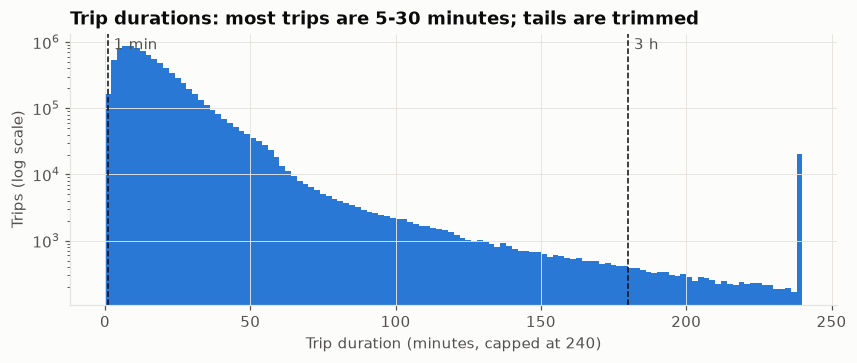

In [4]:
print(f"Kept {audit['final_rows']:,} of {audit['raw_rows']:,} journeys ({audit['final_rows']/audit['raw_rows']:.1%}).")
fig, ax = plt.subplots(figsize=(9, 3.2))
mins = raw['duration_s'].clip(upper=4*3600) / 60
ax.hist(mins, bins=np.arange(0, 241, 2), color=SERIES[0])
for x, lab in ((MIN_DURATION_S/60, '1 min'), (MAX_DURATION_S/60, '3 h')):
    ax.axvline(x, color=INK, lw=1, ls='--'); ax.text(x + 2, ax.get_ylim()[1]*0.85, lab, color=INK_2)
ax.set_yscale('log'); ax.set_xlabel('Trip duration (minutes, capped at 240)'); ax.set_ylabel('Trips (log scale)')
ax.set_title('Trip durations: most trips are 5-30 minutes; tails are trimmed')
save(fig, '01_duration_distribution');

## 3. Station renames and relocations

Station **names** change (renames, relocations, an `_OLD` suffix on retired records), so the stable key is the **station number** (TfL terminal code), which joins to BikePoint's `TerminalName`.

When TfL re-registers a dock it keeps the 6-digit code for the new record and retires the old one by appending 4s (`200025` → `200025444`, `200145` → `2001454444`). `cleaning.remap_station_id` folds those trips back onto the live station.

In [5]:
ids = pd.concat([raw['start_station_id'], raw['end_station_id']]).dropna()
retired = ids[ids.str.len().gt(6) & ids.str[6:].str.fullmatch(r'4+')]
ex = (raw.loc[raw['start_station_id'].isin(retired.unique()), ['start_station_id', 'start_station_name']]
         .drop_duplicates().assign(mapped_to=lambda d: d['start_station_id'].str[:6]))
print(f'{retired.nunique()} retired codes, {len(retired):,} trip-ends remapped')
ex.head(12)

11 retired codes, 58,631 trip-ends remapped


,start_station_id,start_station_name,mapped_to
3,200230444,"Maplin Street, Mile End_OLD",200230
108,200025444,"London Fields, Hackney Central_OLD",200025
1313,300032444,"Victoria & Albert Museum, South Kensington_OLD",300032
1823,200136444,"BBC White City, White City_OLD",200136
1857,200141444,"Westfield Ariel Way, White City_OLD",200141
1925,200134444,"Albany Street, The Regent's Park_OLD",200134
5257,200191444,"Spencer Park, Wandsworth Common_OLD",200191
177384,001085444,"Old Quebec Street, Marylebone_OLD",001085
859305,2001454444,"Gloucester Avenue, Camden Town_OLD",200145
5529807,0010684444,"Norton Folgate, Liverpool Street_OLD",001068


In [6]:
print('Stations seen in journeys:', len(stations), '| matched to BikePoint:', stations['in_bikepoint'].sum())
trip_counts = clean['start_station_id'].value_counts().rename('departures')
um = stations[~stations['in_bikepoint']].set_index('station_id').join(trip_counts).sort_values('departures', ascending=False)
um[['display_name', 'departures']].head(8)

Stations seen in journeys: 807 | matched to BikePoint: 790


,display_name,departures
station_id,,
022180,"Cheapside, Bank",25266.0
001100,"Strand, Strand",18791.0
001043,"Museum of London, Barbican",15158.0
022163,"Southwark Station 2, Southwark",14202.0
300213,"Monier Road, Hackney Wick",13228.0
001048,"Queen Victoria Street, St. Paul's",12523.0
001087,"Belgrave Road, Victoria",12114.0
300250,"Temple Gardens, Temple",10527.0


17 station codes don't appear in today's BikePoint feed. They are two workshops plus live stations that were closed or suspended when BikePoint was snapshotted, so their capacity is unknown. Only **Cheapside, Bank** would otherwise have been in the top 40 (rank 26). It is excluded, and this is noted as a limitation.

## 4. Data-quality check: daily totals

start_ts
2025-08-05     183
2025-12-26    6432
2026-01-01    7701
2026-02-15    8483
2025-12-24    8504
dtype: int64

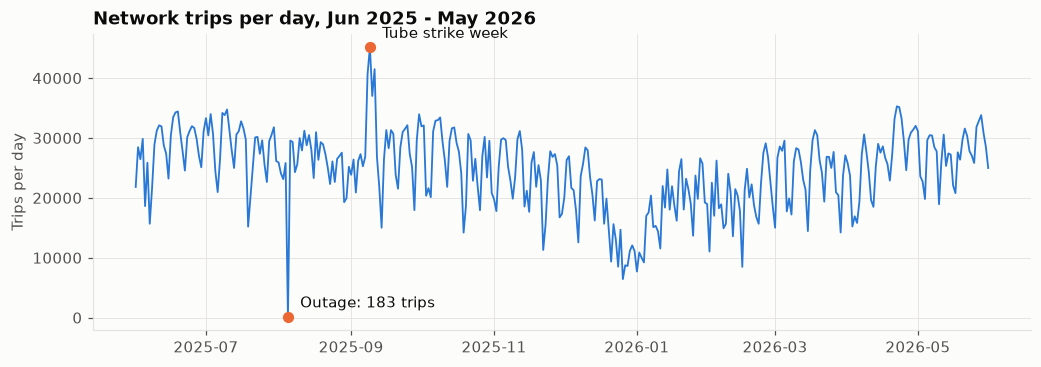

In [7]:
daily = clean.groupby(clean['start_ts'].dt.date).size()
daily.index = pd.to_datetime(daily.index)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily.index, daily.values, color=SERIES[0], lw=1.2)
for d, lab in (('2025-08-05', 'Outage: 183 trips'), ('2025-09-09', 'Tube strike week')):
    d = pd.Timestamp(d); ax.scatter(d, daily[d], color=SERIES[1], s=40, zorder=3)
    ax.annotate(lab, (d, daily[d]), xytext=(8, 6), textcoords='offset points', color=INK)
ax.set_ylabel('Trips per day'); ax.set_title('Network trips per day, Jun 2025 - May 2026')
save(fig, '01_daily_trips_quality');
daily.sort_values().head(5)

* **5 Aug 2025** has 183 trips against ~25k on neighbouring days, and almost none between 01:00 and 22:00. This is a system or data outage, not real demand. It is masked (target set to missing) so it can't distort training, lags or evaluation.
* **8-11 Sep 2025** is the busiest week of the year (up to 45k/day). This matches the London Underground strike that week. It is real demand driven by an external event, so it is kept, and it is a useful test of how models react to events.

## 5. Load into SQLite and aggregate in SQL

The cleaned journeys go into `data/processed/tfl_cycles.db`. The SQL in `sql/` then:
1. `03_top_stations.sql` ranks start stations and keeps the top 40 with known capacity
2. `04_hourly_demand.sql` builds a recursive hourly calendar, cross-joins it with the stations, and left-joins departure and arrival counts, so **every station-hour exists and empty hours are 0**
3. `05_station_profiles.sql` computes each station's peak and weekend shares and AM-peak net flow

In [8]:
con = db.build_database(clean, stations)
print((db.SQL / '04_hourly_demand.sql').read_text())

-- Hourly departures AND arrivals per top station, with every station-hour present.
-- Hours with no trips are filled with 0 using a recursive calendar spine.
DROP TABLE IF EXISTS hourly_demand;
CREATE TABLE hourly_demand AS
WITH RECURSIVE hours(hour_ts) AS (
    SELECT datetime(:start_date)
    UNION ALL
    SELECT datetime(hour_ts, '+1 hour') FROM hours
    WHERE  hour_ts < datetime(:end_date, '+23 hours')
),
dep AS (
    SELECT start_station_id AS station_id, start_hour AS hour_ts, COUNT(*) AS n,
           SUM(bike_model = 'PBSC_EBIKE') AS n_ebike
    FROM   journeys
    WHERE  start_station_id IN (SELECT station_id FROM top_stations)
    GROUP BY 1, 2
),
arr AS (
    SELECT end_station_id AS station_id, end_hour AS hour_ts, COUNT(*) AS n
    FROM   journeys
    WHERE  end_station_id IN (SELECT station_id FROM top_stations)
    GROUP BY 1, 2
)
SELECT  t.station_id,
        h.hour_ts,
        COALESCE(d.n, 0)       AS departures,
        COALESCE(d.n_ebike, 0) AS departures_ebike,
 

In [9]:
q = lambda s: pd.read_sql(s, con)
q('''SELECT COUNT(*) AS rows, COUNT(DISTINCT station_id) AS stations, COUNT(DISTINCT hour_ts) AS hours,
            SUM(departures = 0) AS zero_hours, SUM(departures) AS departures FROM hourly_demand''')

,rows,stations,hours,zero_hours,departures
0,350400,40,8760,115773,1205115


In [10]:
q('SELECT demand_rank, station_id, display_name, nb_docks, departures_per_day FROM top_stations')

,demand_rank,station_id,display_name,nb_docks,departures_per_day
0,1,001072,"Waterloo Station 3, Waterloo",35,162.5
1,2,001075,"Hyde Park Corner, Hyde Park",36,148.8
2,3,002696,"Waterloo Station 1, Waterloo",36,123.3
3,4,001011,"Argyle Street, Kings Cross",45,107.8
4,5,002587,"Wormwood Street, Liverpool Street",15,105.2
5,6,001132,"Albert Gate, Hyde Park",34,100.1
6,7,000960,"Hop Exchange, The Borough",56,99.4
7,8,300083,"Duke Street Hill, London Bridge",21,94.7
8,9,200183,"Battersea Park Road, Nine Elms",27,93.6
9,10,001157,"Black Lion Gate, Kensington Gardens",24,89.7


**Why 40 stations?** The top 40 account for a disproportionate share of trips and include every station type that matters for operations (mainline terminals, City offices, parks). That gives 350k station-hours, which is enough to model seriously and small enough to iterate quickly. Modelling all ~800 stations would add mostly sparse, low-volume series.

In [11]:
share = q('SELECT SUM(departures_12m) AS top FROM top_stations').iloc[0, 0] / len(clean)
print(f'Top 40 stations = {40/len(stations):.1%} of stations but {share:.1%} of all departures')

Top 40 stations = 5.0% of stations but 13.4% of all departures
